In [37]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

In [38]:
df = pd.read_csv("./dataset/amz_uk_price_prediction_dataset.csv")

In [39]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*




In [40]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [41]:
crosstab_result2 = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result2

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


to calculate the proportion as suggested in the top, we neeed to divide the true values divided by total valeus (true + false). To calculate the false we need to add the rows, which is axis=1. 

In [42]:
proportions = (crosstab_result2[True] / crosstab_result2.sum(axis=1))
proportions
best_seller_is_more_prevalent = proportions.sort_values(ascending=False)
best_seller_is_more_prevalent

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Length: 296, dtype: float64

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [43]:
from scipy.stats import chi2_contingency

In [44]:
# Chi-square test for 'category' and 'isBestSeller'
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result2)

In [45]:
a,b,c,d=chi2_contingency(crosstab_result2)

In [46]:
float(chi2_pvalue)

0.0

In [47]:
from scipy.stats.contingency import association
association(crosstab_result2, method='cramer')

0.1222829439760564

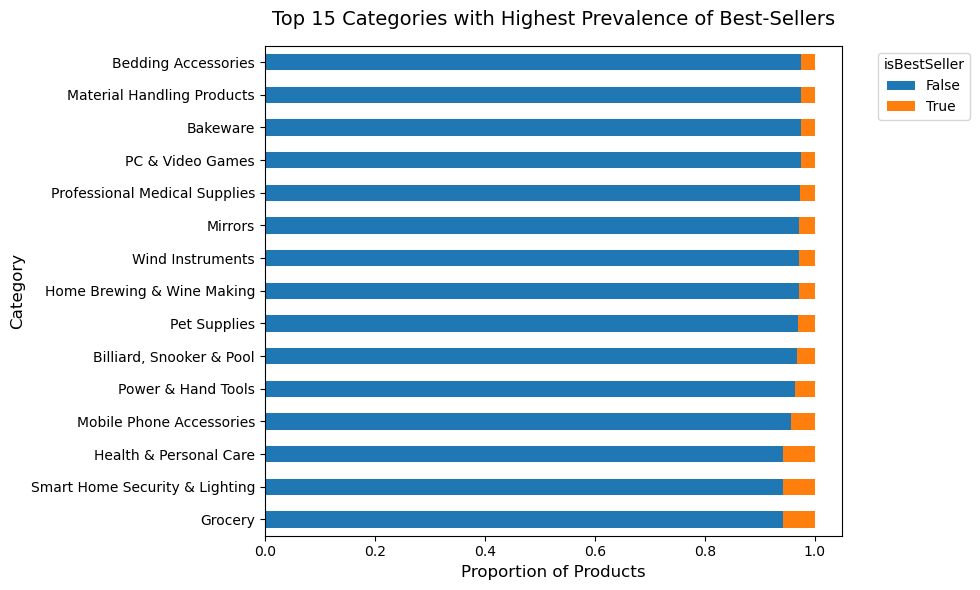

In [48]:
# 1. Calculate proportions normalized by category row totals
crosstab_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

# 2. Grab only the top 15 categories sorted by best-seller prevalence
top_categories = crosstab_prop.sort_values(by=True, ascending=False).head(15)

# 3. Plot a clean, readable stacked horizontal bar chart
top_categories.plot(kind='barh', stacked=True, figsize=(10, 6), color=['#1f77b4', '#ff7f0e'])

# 4. Add clear labels and title
plt.title('Top 15 Categories with Highest Prevalence of Best-Sellers', fontsize=14, pad=15)
plt.xlabel('Proportion of Products', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.legend(title='isBestSeller', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [55]:
def actual_data(data_frame):
    Q1 = data_frame['price'].quantile(0.25)
    Q3 = data_frame['price'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter the entire DataFrame based on the price boundaries
    filtered_df = data_frame[(data_frame['price'] >= lower_bound) & (data_frame['price'] <= upper_bound)]
    return filtered_df

# 2. Run the function passing the whole 'df'
data_considered = actual_data(df)
data_considered 

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


/var/folders/8c/vz1njqts14d0ylxcpzv3_0hr0000gn/T/ipykernel_878/1791745298.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_violin, x="price", y="category", palette="coolwarm")


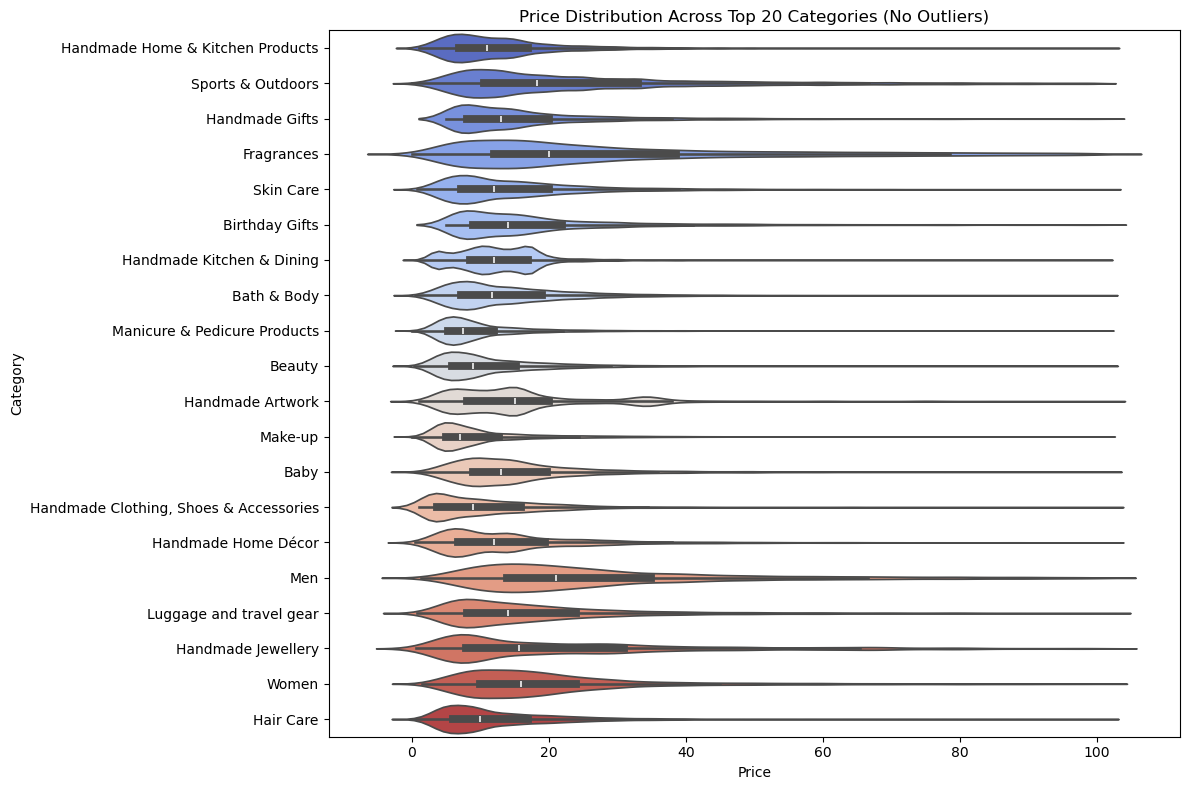

In [56]:
# 2. Run the function passing the whole 'df'
data_considered = actual_data(df)

# 3. Get the top 20 categories based on count
top_20_categories = data_considered["category"].value_counts().head(20).index
df_violin = data_considered[data_considered["category"].isin(top_20_categories)]

# 4. Plot the clean violin plot
plt.figure(figsize=(12, 8))
sns.violinplot(data=df_violin, x="price", y="category", palette="coolwarm")
plt.title("Price Distribution Across Top 20 Categories (No Outliers)")
plt.xlabel("Price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [58]:
# Calculate median price for all categories and sort from highest to lowest
median_prices = data_considered.groupby('category')['price'].median().sort_values(ascending=False)

# Display the top categories with the highest median prices
print(median_prices.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Birthday Gifts'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Skin Care'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Hair Care'),
  Text(6, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(7, 0, 'Beauty'),
  Text(8, 0, 'Make-up'),
  Text(9, 0, 'Manicure & Pedicure Products')])

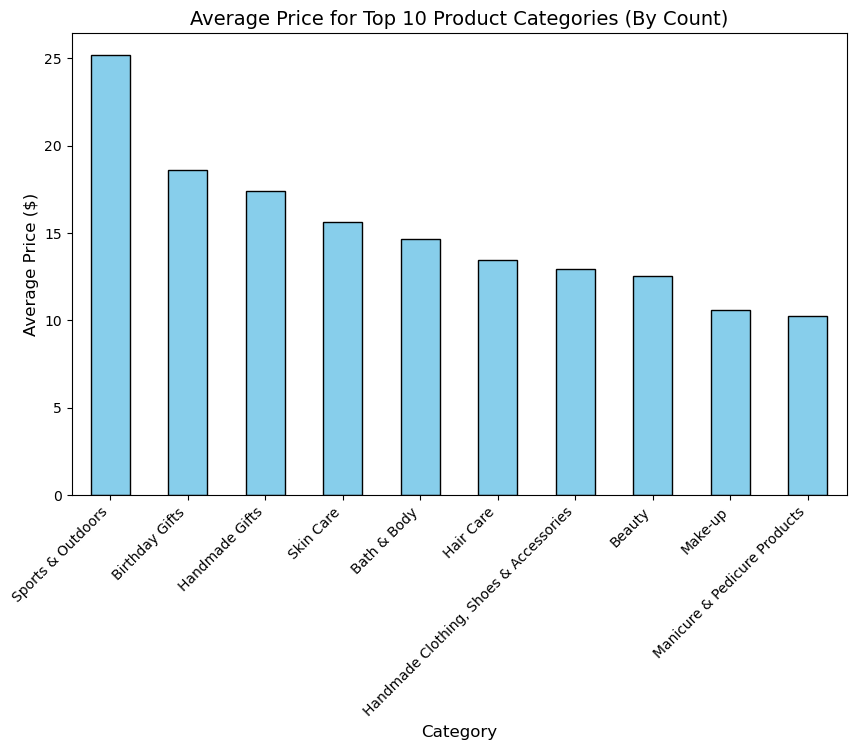

In [59]:
# Get the names of the top 10 categories based on product count
top_10_by_count = data_considered['category'].value_counts().head(10).index

# Filter data to only include these 10 categories
df_bar = data_considered[data_considered['category'].isin(top_10_by_count)]

# Calculate the average price for these categories and sort them
avg_prices_top_10 = df_bar.groupby('category')['price'].mean().sort_values(ascending=False)

# Plot the bar chart
plt.figure(figsize=(10, 6))
avg_prices_top_10.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Average Price for Top 10 Product Categories (By Count)', fontsize=14)
plt.ylabel('Average Price ($)', fontsize=12)
plt.xlabel('Category', fontsize=12)
plt.xticks(rotation=45, ha='right')

In [60]:
# Calculate average price for all categories and sort descending
highest_avg_prices = data_considered.groupby('category')['price'].mean().sort_values(ascending=False)

# Display the top 5 highest average price categories
print(highest_avg_prices.head(5))

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


/var/folders/8c/vz1njqts14d0ylxcpzv3_0hr0000gn/T/ipykernel_878/1760937134.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x='stars', y='category', palette='Set2')


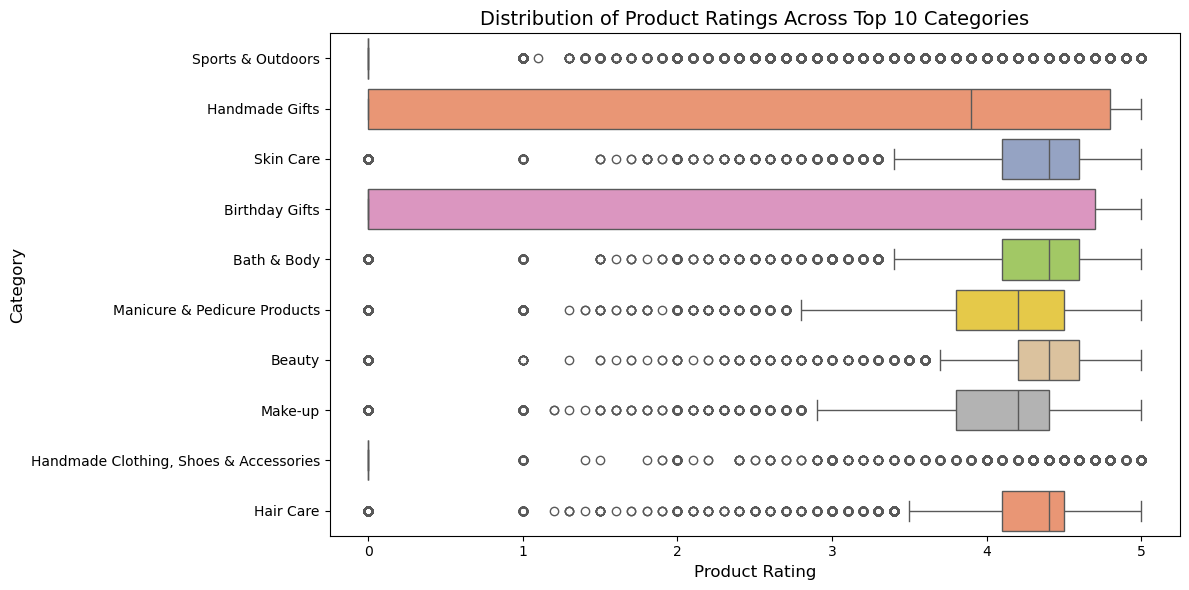

In [62]:
# Get the names of the top 10 categories based on product count
top_10_categories = data_considered['category'].value_counts().head(10).index

# Filter data to only include these 10 categories
df_box = data_considered[data_considered['category'].isin(top_10_categories)]

# Plot side-by-side box plots for ratings
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_box, x='stars', y='category', palette='Set2')
plt.title('Distribution of Product Ratings Across Top 10 Categories', fontsize=14)
plt.xlabel('Product Rating', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

In [64]:
# Calculate median rating for all categories and sort descending
highest_median_ratings = data_considered.groupby('category')['stars'].median().sort_values(ascending=False)

# Display the top 5 highest median rating categories
print(highest_median_ratings.head(5))

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64
